# 04.1 - Experimentos com Regressão Logística

**Objetivo:** avaliar regressão logística como modelo principal, comparar com outros modelos interpretáveis, e entender os coeficientes.

---

## Roteiro
1. Carregar dados já processados
2. Testar regressão logística com variações de `C` e solver
3. Comparar com LDA e SVM Linear
4. Verificar desempenho no holdout
5. Analisar coeficientes por classe
6. Conclusão para o notebook 4


In [9]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC

OUTPUT_DIR = './pipeline_output/'
X_train = np.load(OUTPUT_DIR + 'X_train_processed.npy')
X_val = np.load(OUTPUT_DIR + 'X_val_processed.npy')
y_train = np.load(OUTPUT_DIR + 'y_train.npy')
y_val = np.load(OUTPUT_DIR + 'y_val.npy')

print('Treino:', X_train.shape)
print('Validação:', X_val.shape)


Treino: (2505, 9)
Validação: (627, 9)


## 1. Teste de regressão logística

Vamos testar combinações pequenas de `C` e solver para ver se a regressão logística bate o baseline atual.


In [10]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

logreg_grid = [
    {'C': 0.1, 'solver': 'lbfgs'},
    {'C': 1.0, 'solver': 'lbfgs'},
    {'C': 3.0, 'solver': 'lbfgs'},
    {'C': 10.0, 'solver': 'lbfgs'},
    {'C': 1.0, 'solver': 'newton-cg'},
]

rows = []
for cfg in logreg_grid:
    model = LogisticRegression(
        max_iter=4000,
        random_state=42,
        C=cfg['C'],
        solver=cfg['solver'],
    )
    acc = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    rows.append({
        'C': cfg['C'],
        'solver': cfg['solver'],
        'acc_mean': acc.mean(),
        'acc_std': acc.std(),
        'f1_mean': f1.mean(),
        'f1_std': f1.std(),
    })
    print(cfg, '->', round(acc.mean(), 4), round(f1.mean(), 4))

logreg_results = pd.DataFrame(rows).sort_values('acc_mean', ascending=False)
print(logreg_results.to_string(index=False))


{'C': 0.1, 'solver': 'lbfgs'} -> 0.6399 0.634
{'C': 1.0, 'solver': 'lbfgs'} -> 0.6491 0.6444
{'C': 3.0, 'solver': 'lbfgs'} -> 0.6499 0.6455
{'C': 10.0, 'solver': 'lbfgs'} -> 0.6491 0.6446
{'C': 1.0, 'solver': 'newton-cg'} -> 0.6495 0.6448
   C    solver  acc_mean  acc_std  f1_mean   f1_std
 3.0     lbfgs  0.649895 0.019784 0.645472 0.019350
 1.0 newton-cg  0.649498 0.020601 0.644783 0.019653
 1.0     lbfgs  0.649100 0.020092 0.644390 0.019061
10.0     lbfgs  0.649095 0.018263 0.644616 0.018472
 0.1     lbfgs  0.639912 0.022317 0.633993 0.020942


## 2. Comparação com modelos interpretáveis

Agora comparamos a melhor regressão logística contra LDA e SVM Linear.


In [11]:
best_row = logreg_results.iloc[0]
best_logreg = LogisticRegression(
    max_iter=4000,
    random_state=42,
    C=float(best_row['C']),
    solver=best_row['solver'],
)

models = {
    'Logistic Regression': best_logreg,
    'LDA': LinearDiscriminantAnalysis(),    
    'SVM Linear': SVC(kernel='linear', random_state=42),
}

compare_rows = []
for name, model in models.items():
    acc = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    compare_rows.append({'model': name, 'acc_mean': acc.mean(), 'f1_mean': f1.mean()})

compare_df = pd.DataFrame(compare_rows).sort_values('acc_mean', ascending=False)
print(compare_df.to_string(index=False))


              model  acc_mean  f1_mean
Logistic Regression  0.649895 0.645472
         SVM Linear  0.646306 0.645485
                LDA  0.632331 0.633833


## 3. Avaliação no holdout

Vamos conferir se a regressão logística também fica forte no conjunto de validação separado.


In [12]:
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    print(name)
    print('acc:', round(accuracy_score(y_val, pred), 4), 'f1:', round(f1_score(y_val, pred, average='macro'), 4))
    print(classification_report(y_val, pred))
    print('-' * 60)


Logistic Regression
acc: 0.6667 f1: 0.662
              precision    recall  f1-score   support

           1       0.72      0.82      0.77       216
           2       0.55      0.57      0.56       201
           3       0.73      0.60      0.65       210

    accuracy                           0.67       627
   macro avg       0.67      0.66      0.66       627
weighted avg       0.67      0.67      0.66       627

------------------------------------------------------------
LDA
acc: 0.6571 f1: 0.6547
              precision    recall  f1-score   support

           1       0.73      0.79      0.76       216
           2       0.53      0.63      0.58       201
           3       0.75      0.54      0.63       210

    accuracy                           0.66       627
   macro avg       0.67      0.66      0.65       627
weighted avg       0.67      0.66      0.66       627

------------------------------------------------------------
SVM Linear
acc: 0.6571 f1: 0.6539
             

## 4. Coeficientes da regressão logística

Os coeficientes mostram quais features puxam cada classe para cima ou para baixo.


Coeficientes da regressão logística:
          sex_I  sex_M  length  diameter  height  whole_weight  shucked_weight  viscera_weight  shell_weight
classe_1  0.644  0.014   0.375    -0.602  -0.464        -1.676           2.042           0.083        -1.204
classe_2 -0.149 -0.005   0.050     0.416   0.167        -1.227           0.508           0.304         0.253
classe_3 -0.496 -0.009  -0.425     0.187   0.297         2.903          -2.550          -0.386         0.951


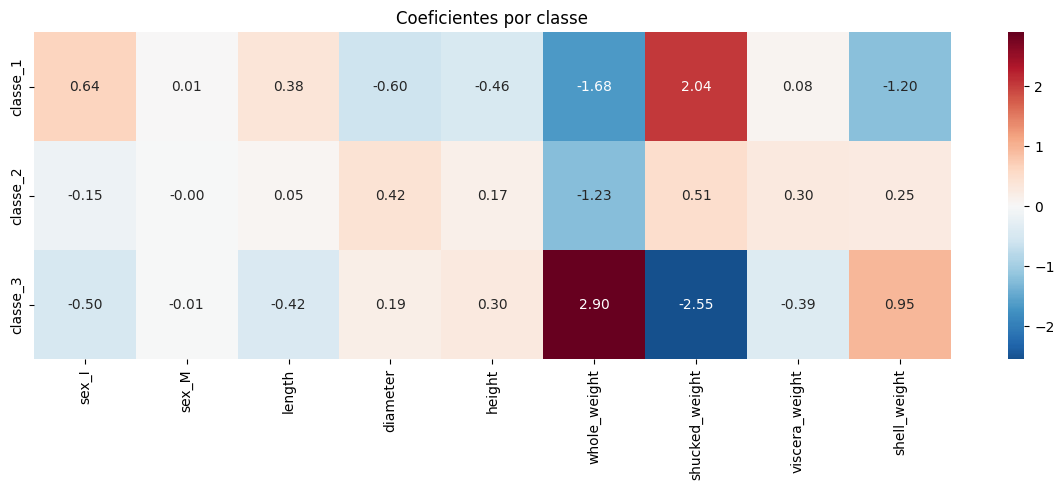

In [13]:
best_logreg.fit(X_train, y_train)
coef_df = pd.DataFrame(best_logreg.coef_, columns=[
    'sex_I', 'sex_M', 'length', 'diameter', 'height',
    'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight'
], index=['classe_1', 'classe_2', 'classe_3'])

print('Coeficientes da regressão logística:')
print(coef_df.round(3).to_string())

plt.figure(figsize=(12, 5))
sns.heatmap(coef_df, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Coeficientes por classe')
plt.tight_layout()
plt.show()


## 5. Conclusão

Registre aqui se a regressão logística deve substituir o SVM RBF como modelo final.


In [14]:
print('Notebook 04.1 pronto para comparar com a decisão atual.')
print('Se a Logistic Regression ficar muito próxima do SVM, vale usar ela no trabalho final.')


Notebook 04.1 pronto para comparar com a decisão atual.
Se a Logistic Regression ficar muito próxima do SVM, vale usar ela no trabalho final.
